# 01: Exploração do dataset público (coleira)

Objetivo: **olhar** os dados antes de treinar qualquer coisa. Ver como cada comportamento
aparece no sinal da coleira, quanto tem de cada classe e se as classes parecem separáveis.

- Dados: Vehkaoja et al. (2022) / Kumpulainen et al. (2021). Detalhes em `docs/dataset-publico.md`.
- Só o sensor do pescoço, já reamostrado a 50 Hz e saturado em ±16 g / ±2000 dps (ADR 0005).
- Toda a lógica fica em `coleira_ml.public_dataset`. Este notebook só explora.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from coleira_ml.classes import Behavior
from coleira_ml.public_dataset import TARGET_HZ, load_collar

df = load_collar(Path("../data/public"))
df["acc_mag"] = np.sqrt(df.ax**2 + df.ay**2 + df.az**2)  # 7º canal do contrato 4.3
df["gyro_mag"] = np.sqrt(df.gx**2 + df.gy**2 + df.gz**2)
KNOWN = [b for b in Behavior if b != Behavior.DESCONHECIDO and (df.class_id == b).any()]
COLORS = dict(zip(KNOWN, plt.cm.tab10.colors, strict=False))
print(
    f"{len(df):,} amostras a {TARGET_HZ} Hz = {len(df) / TARGET_HZ / 3600:.1f} h;",
    f"{df.dog_id.nunique()} cães",
)

5,305,534 amostras a 50 Hz = 29.5 h; 45 cães


## Quanto tem de cada classe

In [2]:
summary = pd.DataFrame(
    {
        "minutos": df.groupby("class_id").size() / TARGET_HZ / 60,
        "cães": df.groupby("class_id").dog_id.nunique(),
    }
)
summary.index = [Behavior(i).name for i in summary.index]
summary.round(1).sort_values("minutos", ascending=False)

,minutos,cães
DESCONHECIDO,909.9,45
PARADO,500.2,45
CORRENDO,156.0,45
ANDANDO,139.0,45
COMENDO,45.7,42
BEBENDO,10.8,35
CHACOALHANDO,7.0,45


## Um trecho de cada comportamento

6 segundos do primeiro trecho contínuo de cada classe. Linha de cima: acelerômetro (g),
com a magnitude em preto. Linha de baixo: giroscópio (°/s).

O que procurar: parado é quase reto (só a gravidade), andar e correr são periódicos com
ritmos diferentes, e chacoalhar é uma explosão curta e enorme, principalmente no giroscópio.

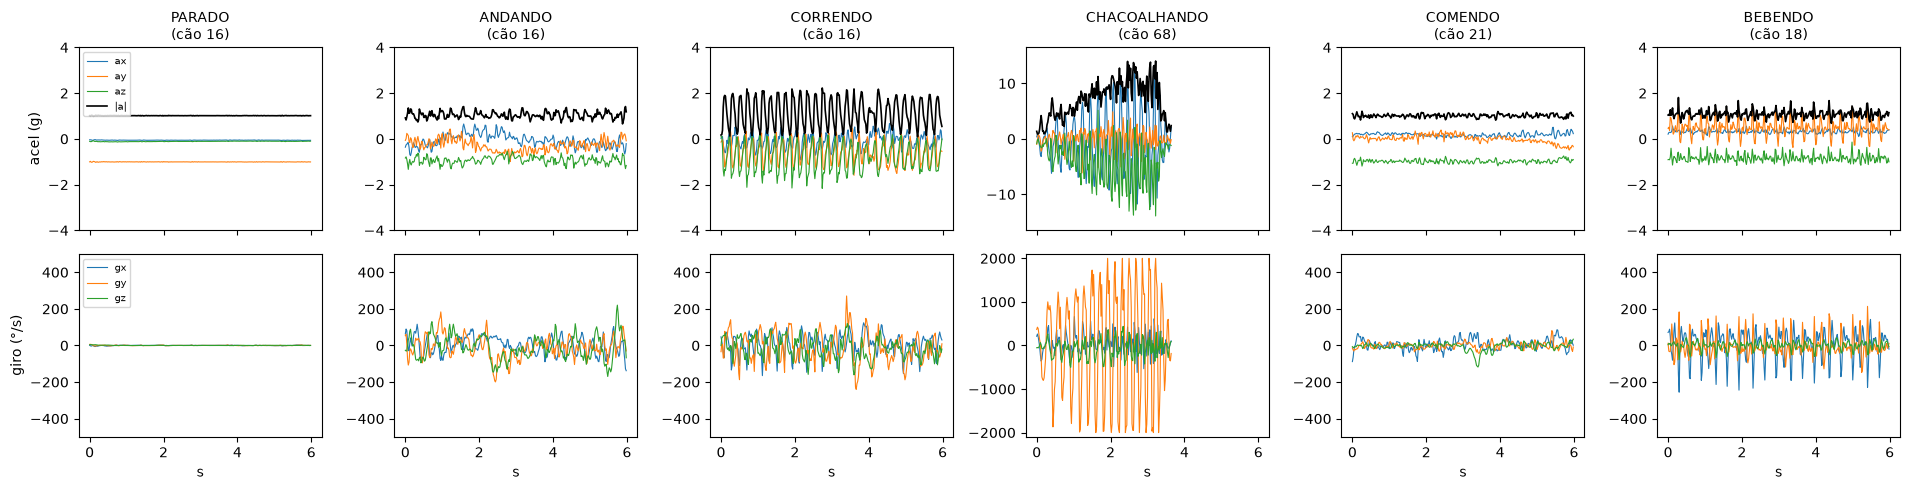

In [3]:
def first_run(cls, seconds=6):
    n = seconds * TARGET_HZ
    is_cls = (df.class_id == cls).to_numpy()
    # início de trechos contínuos da classe dentro do mesmo teste
    seg_id = (df.class_id != df.class_id.shift()).cumsum()
    for _, g in df[is_cls].groupby(seg_id[is_cls]):
        if len(g) >= n:
            mid = len(g) // 2
            return g.iloc[max(0, mid - n // 2) : max(0, mid - n // 2) + n]
    g = df[is_cls].groupby(seg_id[is_cls]).size().idxmax()
    return df[is_cls][seg_id[is_cls] == g]


fig, axes = plt.subplots(2, len(KNOWN), figsize=(3.2 * len(KNOWN), 5), sharex=True)
for j, cls in enumerate(KNOWN):
    seg = first_run(cls)
    t = np.arange(len(seg)) / TARGET_HZ
    for c in ["ax", "ay", "az"]:
        axes[0, j].plot(t, seg[c], lw=0.8, label=c)
    axes[0, j].plot(t, seg.acc_mag, "k", lw=1.2, label="|a|")
    for c in ["gx", "gy", "gz"]:
        axes[1, j].plot(t, seg[c], lw=0.8, label=c)
    axes[0, j].set_title(f"{Behavior(cls).name}\n(cão {seg.dog_id.iloc[0]})", fontsize=10)
    axes[0, j].set_ylim(-4, 4) if cls != Behavior.CHACOALHANDO else axes[0, j].set_ylim(-16.5, 16.5)
    axes[1, j].set_ylim(-500, 500) if cls != Behavior.CHACOALHANDO else axes[1, j].set_ylim(
        -2100, 2100
    )
    axes[1, j].set_xlabel("s")
axes[0, 0].set_ylabel("acel (g)")
axes[1, 0].set_ylabel("giro (°/s)")
axes[0, 0].legend(fontsize=7, loc="upper left")
axes[1, 0].legend(fontsize=7, loc="upper left")
fig.tight_layout()

## Intensidade: desvio padrão da magnitude em janelas de 2 s

Uma feature só (o quanto a magnitude da aceleração varia em 2 s) já separa bem
parado / andando / correndo / chacoalhar. Comer e beber ficam misturados com parado,
e por isso eles precisam de mais que intensidade (e são Fase 6).

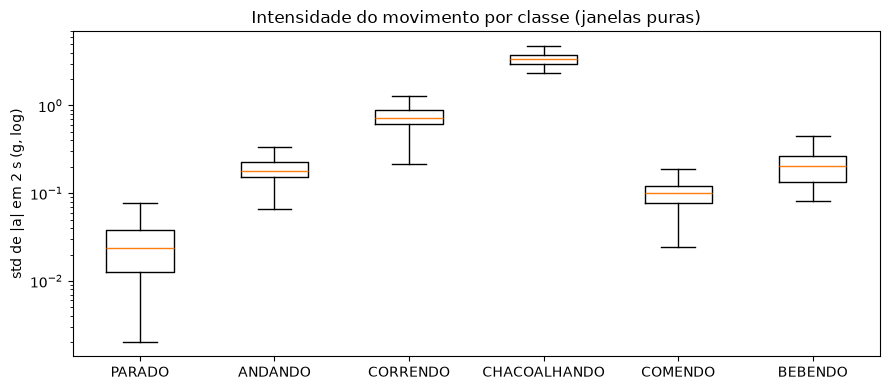

In [4]:
W = 2 * TARGET_HZ
d = df[df.class_id != Behavior.DESCONHECIDO].copy()
d["win"] = d.groupby(["dog_id", "test_num"]).cumcount() // W
grp = d.groupby(["dog_id", "test_num", "win"])
win = grp.agg(cls=("class_id", "first"), pure=("class_id", "nunique"), std=("acc_mag", "std"))
win = win[win.pure == 1]

fig, ax = plt.subplots(figsize=(9, 4))
data = [win[win.cls == c]["std"].clip(lower=1e-3) for c in KNOWN]
ax.boxplot(data, tick_labels=[Behavior(c).name for c in KNOWN], showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("std de |a| em 2 s (g, log)")
ax.set_title("Intensidade do movimento por classe (janelas puras)")
fig.tight_layout()

## Ritmo: espectro da magnitude por classe

Média do espectro (Welch) de |a| por classe.

Pegadinha: a **magnitude** |a| oscila no **dobro** da frequência do movimento. Um balanço
para um lado e para o outro gera dois picos de |a|, já que o sinal (+/−) some. Então
uma passada de ~2 Hz aparece em ~4 Hz, e um chacoalhão de ~5 Hz aparece em ~10 Hz.

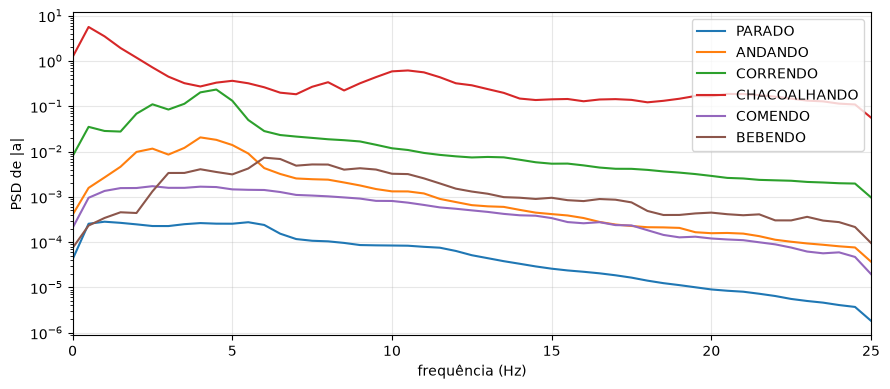

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for cls in KNOWN:
    psds = []
    for _, g in d[d.class_id == cls].groupby(["dog_id", "test_num"]):
        x = g.acc_mag.to_numpy()
        if len(x) >= W:
            f, p = welch(x - x.mean(), fs=TARGET_HZ, nperseg=W)
            psds.append(p)
    ax.semilogy(f, np.mean(psds, axis=0), label=Behavior(cls).name, color=COLORS[cls])
ax.set_xlabel("frequência (Hz)")
ax.set_ylabel("PSD de |a|")
ax.set_xlim(0, 25)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

## Duração dos chacoalhões (para o ADR 0002)

In [6]:
seg = (
    (df.class_id != df.class_id.shift())
    | (df.dog_id != df.dog_id.shift())
    | (df.test_num != df.test_num.shift())
).cumsum()
runs = df.assign(seg=seg).groupby("seg").agg(cls=("class_id", "first"), n=("class_id", "size"))
shake_s = runs[runs.cls == Behavior.CHACOALHANDO].n / TARGET_HZ
print(f"{len(shake_s)} chacoalhões")
shake_s.describe(percentiles=[0.1, 0.5, 0.9]).round(2)

286 chacoalhões


count    286.00
mean       1.46
std        0.69
min        0.06
10%        0.62
50%        1.42
90%        2.42
max        3.66
Name: n, dtype: float64

## Conclusões (2026-11-16)

1. **Intensidade sozinha já separa 0 → 1 → 2 → 4.** O desvio padrão de |a| em 2 s cresce
   ~10× a cada degrau: parado ~0,02 g, andando ~0,2 g, correndo ~0,7 g, chacoalhando ~3,5 g.
   As caixas quase não se sobrepõem, o que é um bom sinal para a meta de ≥ 85% da Fase 0.
2. **Chacoalhar é inconfundível:** |a| chega a 10–15 g e o giroscópio **satura em
   ±2000 °/s**, como previsto no ADR 0005. Duração mediana de **1,4 s** (90% < 2,4 s),
   o que confirma a premissa do ADR 0002: maioria de 5 janelas apagaria esses eventos.
3. **Andar × correr:** os dois têm pico em ~4 Hz em |a| (passada de ~2 Hz), mas correr tem
   ~10× mais energia. O ritmo é parecido; o que muda é a força.
4. **Comer se mistura com parado e andando** em intensidade (~0,1 g). Precisa de outra
   pista (postura da cabeça, padrão de mastigação, áudio), e isso confirma por que ficou
   para a Fase 6.
5. **Beber tem uma assinatura própria:** um pico em ~6 Hz no espectro, que deve ser a
   lambida. É mais promissor que comer.
6. **Desbalanceamento forte:** 500 min de parado contra 7 min de chacoalhar. Vamos precisar
   de class weights e de olhar F1 por classe e acurácia balanceada, nunca a acurácia simples.